# Speech and Silent Periods Measurement

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pydub import AudioSegment
from pydub.silence import detect_silence, detect_nonsilent
import random

In [ ]:
# ======================================================
# Global dictionaries
# ======================================================

results_dict = {}  

# Global lists to store individual segment values for histogram plotting
silence_duration_hist_data = []  # each entry: {Model, Gender, Type, Duration}
speech_duration_hist_data = []   # each entry: {Model, Gender, Type, Duration}
silent_segment_count_data = []   # each entry: {Model, Gender, Type, Count}
speech_segment_count_data = []   # each entry: {Model, Gender, Type, Count}

# ======================================================
# Audio processing functions
# ======================================================

def load_audio(file_path):
    return AudioSegment.from_wav(file_path)

def detect_silence_and_speech(audio, silence_thresh=-60, min_silence_len=50):
    """
    Detect silent and non-silent segments. Then, to restrict analysis only
    to the active speech region, we clip any silent segments that occur before 
    the first or after the last spoken segment.
    """
    # Detect all segments
    silent_segments = detect_silence(audio, min_silence_len=min_silence_len, silence_thresh=silence_thresh)
    nonsilent_segments = detect_nonsilent(audio, min_silence_len=min_silence_len, silence_thresh=silence_thresh)

    if nonsilent_segments:
        effective_start = nonsilent_segments[0][0]
        effective_end = nonsilent_segments[-1][1]
        effective_silent_segments = []
        for start, end in silent_segments:
            # Only consider parts that fall inside the active region
            if end <= effective_start or start >= effective_end:
                continue
            clipped_start = max(start, effective_start)
            clipped_end = min(end, effective_end)
            effective_silent_segments.append([clipped_start, clipped_end])
        silent_segments = effective_silent_segments

    # Calculate durations in ms
    silence_durations = [end - start for start, end in silent_segments]
    total_silence_duration = sum(silence_durations)
    speech_durations = [end - start for start, end in nonsilent_segments]
    total_speech_duration = sum(speech_durations)
    return silent_segments, nonsilent_segments, silence_durations, total_silence_duration, speech_durations, total_speech_duration

def process_folder(folder_path, return_per_file_counts=False):
    """
    Process all .wav files in a folder. For each file, collect the list of silent 
    and speech segment durations. Also count the total number of segments.
    
    If return_per_file_counts=True, also return a list of silent-segment counts
    per file for bootstrapping.
    """
    silence_durations_all = []
    speech_durations_all = []
    silent_segment_count = 0
    speech_segment_count = 0
    
    per_file_silent_counts = [] if return_per_file_counts else None
    
    for file_name in os.listdir(folder_path):
        if file_name.endswith(".wav"):
            file_path = os.path.join(folder_path, file_name)
            audio = load_audio(file_path)
            (silent_segments, nonsilent_segments, 
             silence_durations, _, 
             speech_durations, _) = detect_silence_and_speech(audio)
            
            # Accumulate
            silence_durations_all.extend(silence_durations)
            speech_durations_all.extend(speech_durations)
            
            # Count segments
            num_silent_segments = len(silent_segments)
            num_speech_segments = len(nonsilent_segments)
            silent_segment_count += num_silent_segments
            speech_segment_count += num_speech_segments
            
            if return_per_file_counts:
                per_file_silent_counts.append(num_silent_segments)
    
    if return_per_file_counts:
        return (silence_durations_all, speech_durations_all, 
                silent_segment_count, speech_segment_count, 
                per_file_silent_counts)
    else:
        return (silence_durations_all, speech_durations_all, 
                silent_segment_count, speech_segment_count)

def compute_statistics(silence_durations, speech_durations, silent_segment_count, speech_segment_count):
    avg_silence_duration = np.mean(silence_durations) if silence_durations else 0
    avg_speech_duration = np.mean(speech_durations) if speech_durations else 0
    return avg_silence_duration, avg_speech_duration, silent_segment_count, speech_segment_count

# ======================================================
# Bootstrapping function
# ======================================================

def bootstrap_silent_segment_count_ratio(counts_true, counts_gen, n_iterations=1000, ci=95):
    """
    Performs bootstrap resampling of the ratio of sums:
        ratio = sum(gen) / sum(true)
    Returns the mean of bootstrap distribution and an approximate symmetric error
    (based on std * z-value).
    """
    
    if len(counts_true) == 0 or len(counts_gen) == 0 or sum(counts_true) == 0:
        return 0, 0
    
    ratio_samples = []
    n_true = len(counts_true)
    n_gen = len(counts_gen)
    
    # Perform the bootstrap
    for _ in range(n_iterations):
        sample_true = [random.choice(counts_true) for _ in range(n_true)]
        sample_gen  = [random.choice(counts_gen)  for _ in range(n_gen)]
        ratio = sum(sample_gen) / sum(sample_true)
        ratio_samples.append(ratio)
    
    ratio_samples = np.array(ratio_samples)
    ratio_mean = ratio_samples.mean()
    ratio_std  = ratio_samples.std()
    
    # For a normal approx of the CI:
    # z for ~95% CI is ~1.96
    z = 1.96
    err = z * ratio_std
    return ratio_mean, err

# ======================================================
# Update results and collect raw data for histograms
# ======================================================

def update_results(model_name, gender, audio_type,
                   avg_silence, avg_speech, 
                   silent_count, speech_count,
                   silence_durations, speech_durations,
                   ratio_norm=None, ratio_norm_err=None):
    """
    Extended to optionally include ratio_norm and ratio_norm_err in the 
    results dictionary. ratio_norm_err is for plotting error bars.
    """
    if model_name not in results_dict:
        results_dict[model_name] = {}
    if gender not in results_dict[model_name]:
        results_dict[model_name][gender] = {}
    
    # Basic metrics
    results_dict[model_name][gender][audio_type] = {
        "Average Silence Duration (ms)": avg_silence,
        "Average Speech Duration (ms)": avg_speech,
        "Silent Segment Count": silent_count,
        "Speech Segment Count": speech_count
    }
    
    # If ratio_norm is given, store it
    if ratio_norm is not None:
        results_dict[model_name][gender][audio_type]["Silent Segment Count Norm"] = ratio_norm
    if ratio_norm_err is not None:
        results_dict[model_name][gender][audio_type]["Silent Segment Count Norm Err"] = ratio_norm_err
    
    for duration in silence_durations:
        silence_duration_hist_data.append({
            "Model": model_name,
            "Gender": gender,
            "Type": audio_type,
            "Duration": duration
        })
    for duration in speech_durations:
        speech_duration_hist_data.append({
            "Model": model_name,
            "Gender": gender,
            "Type": audio_type,
            "Duration": duration
        })
    
    silent_segment_count_data.append({
        "Model": model_name,
        "Gender": gender,
        "Type": audio_type,
        "Count": silent_count
    })
    speech_segment_count_data.append({
        "Model": model_name,
        "Gender": gender,
        "Type": audio_type,
        "Count": speech_count
    })

# ======================================================
# Save results to CSV 
# ======================================================

def save_results_to_csv(csv_path):
    data = []
    for model, genders in results_dict.items():
        for gender, types in genders.items():
            for audio_type, metrics in types.items():
                row = {"Model": model, "Gender": gender, "Type": audio_type}
                row.update(metrics)
                if "Silent Segment Count Norm" not in row:
                    row["Silent Segment Count Norm"] = np.nan
                if "Silent Segment Count Norm Err" not in row:
                    row["Silent Segment Count Norm Err"] = np.nan
                data.append(row)
    df = pd.DataFrame(data)
    df.to_csv(csv_path, index=False)

# ======================================================
# Main processing function 
# ======================================================

def main(model_name, gender, folder_true, folder_gen):
    # Process the true audios
    ret_true = process_folder(folder_true, return_per_file_counts=True)
    (silence_durations_all_true, speech_durations_all_true, 
     silent_count_true, speech_count_true, 
     per_file_silent_counts_true) = ret_true
    
    avg_silence_true, avg_speech_true, _, _ = compute_statistics(
        silence_durations_all_true, 
        speech_durations_all_true, 
        silent_count_true, 
        speech_count_true
    )
    
    update_results(
        model_name, gender, "true", 
        avg_silence_true, avg_speech_true,
        silent_count_true, speech_count_true,
        silence_durations_all_true, speech_durations_all_true
    )
    
    # Process the gen audios
    ret_gen = process_folder(folder_gen, return_per_file_counts=True)
    (silence_durations_all_gen, speech_durations_all_gen, 
     silent_count_gen, speech_count_gen, 
     per_file_silent_counts_gen) = ret_gen
    
    avg_silence_gen, avg_speech_gen, _, _ = compute_statistics(
        silence_durations_all_gen, 
        speech_durations_all_gen, 
        silent_count_gen, 
        speech_count_gen
    )
    
    # Compute ratio of sums for silent segment counts
    if silent_count_true == 0:
        ratio_of_sums = 0
    else:
        ratio_of_sums = silent_count_gen / silent_count_true
    
    # Bootstrap 
    ratio_mean, ratio_err = bootstrap_silent_segment_count_ratio(
        per_file_silent_counts_true,
        per_file_silent_counts_gen,
        n_iterations=2000,  
        ci=95
    )
        
    update_results(
        model_name, gender, "gen", 
        avg_silence_gen, avg_speech_gen,
        silent_count_gen, speech_count_gen,
        silence_durations_all_gen, speech_durations_all_gen,
        ratio_norm=ratio_of_sums,
        ratio_norm_err=ratio_err
    )

# ======================================================
# Plotting 
# ======================================================

def plot_gen_ratio(csv_file, 
                   metric="Silent Segment Count Norm", 
                   metric_err="Silent Segment Count Norm Err",
                   plot_name="ratio_plot"):
    """
    Plot the ratio of gen/true silent segments for each model (x-axis),
    separated by gender, with error bars from bootstrapping.
    """
    plt.rcdefaults()

    df = pd.read_csv(csv_file)
    df_gen = df[df["Type"] == "gen"].copy()
    pivot_df = df_gen.pivot_table(index="Model", columns="Gender", values=metric)
    pivot_df_err = df_gen.pivot_table(index="Model", columns="Gender", values=metric_err)
    
    # Rename columns
    pivot_df.rename(columns={
        "male": "Male (synthesis)",
        "female": "Female (synthesis)"
    }, inplace=True)
    pivot_df_err.rename(columns={
        "male": "Male (synthesis)",
        "female": "Female (synthesis)"
    }, inplace=True)

    # Order the models on the x-axis
    pivot_df = pivot_df[["Male (synthesis)", "Female (synthesis)"]]
    pivot_df_err = pivot_df_err[["Male (synthesis)", "Female (synthesis)"]]    
    models = ["Fr_g", "Fr_p", "Wa_g", "Wa_p"]
    pivot_df = pivot_df.reindex(models)
    pivot_df_err = pivot_df_err.reindex(models)
    
    # Extract male/female values
    means_male = pivot_df["Male (synthesis)"].values
    means_female = pivot_df["Female (synthesis)"].values
    
    err_male = pivot_df_err["Male (synthesis)"].values
    err_female = pivot_df_err["Female (synthesis)"].values
    
    # Prepare x positions
    x_pos = np.arange(len(models))
    bar_width = 0.35
    offset = bar_width / 2
    
    # colors 
    colors_male = plt.cm.Set2(0)   
    colors_female = plt.cm.Set2(1) 
    alpha = 0.7

    fig, ax = plt.subplots()
    
    # Plot bars for Male
    ax.bar(
        x_pos - offset, 
        means_male,
        yerr=err_male,            
        capsize=3,                
        width=bar_width,
        color=colors_male,
        alpha=alpha,
        label="Male (synthesis)"
    )

    # Plot bars for Female
    ax.bar(
        x_pos + offset, 
        means_female,
        yerr=err_female,         
        capsize=3,
        width=bar_width,
        color=colors_female,
        alpha=alpha,
        label="Female (synthesis)"
    )
    
    ax.axhline(y=1, color="black", linestyle="--", linewidth=1)
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.set_axisbelow(True)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(models, rotation=0, ha="right")
    ax.legend()
    
    plt.tight_layout()
    #plt.savefig(f"{plot_name}.png", dpi=500, bbox_inches='tight')
    plt.savefig(f"{plot_name}.pdf", bbox_inches='tight')
    plt.show()


In [ ]:
models = [
    ("Fr_g", "male", "grap_ft_v1/male_true", "grap_ft_v1/male_gen"),
    ("Fr_g", "female", "grap_ft_v1/female_true", "grap_ft_v1/female_gen"),
    ("Wa_g", "male", "grap_w_v1/male_true", "grap_w_v1/male_gen"),
    ("Wa_g", "female", "grap_w_v1/female_true", "grap_w_v1/female_gen"),
    ("Fr_p", "male", "pho_ft/male_true", "pho_ft/male_gen"),
    ("Fr_p", "female", "pho_ft/female_true", "pho_ft/female_gen"),
    ("Wa_p", "male", "pho_w/male_true", "pho_w/male_gen"),
    ("Wa_p", "female", "pho_w/female_true", "pho_w/female_gen")
]

if __name__ == "__main__":
    for model_name, gender, folder1, folder2 in models:
        main(model_name, gender, folder1, folder2)
    
    save_results_to_csv("results_with_bootstrap.csv")

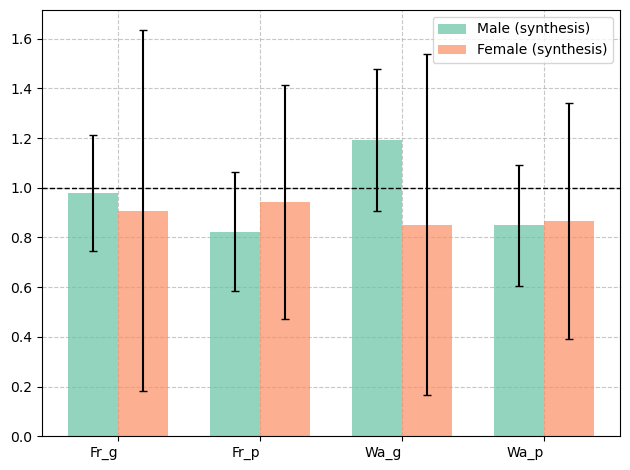

In [ ]:
plot_gen_ratio("results_with_bootstrap.csv",
                metric="Silent Segment Count Norm",
                metric_err="Silent Segment Count Norm Err",
                plot_name="ratio_plot_with_bootstrap")


## BOOTSTRAP PER FILE RATIO

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

from pydub import AudioSegment
from pydub.silence import detect_silence, detect_nonsilent

# Global results dictionary
results_dict = {}

##############################################################################
# Audio-processing and pairing logic
##############################################################################

def detect_silence_and_speech(audio, silence_thresh=-60, min_silence_len=50):
    """
    Detect silent and non-silent segments. Then, to restrict analysis only
    to the active speech region, we clip any silent segments that occur before 
    the first or after the last spoken segment.
    """
    silent_segments = detect_silence(audio, min_silence_len=min_silence_len, silence_thresh=silence_thresh)
    nonsilent_segments = detect_nonsilent(audio, min_silence_len=min_silence_len, silence_thresh=silence_thresh)

    if nonsilent_segments:
        effective_start = nonsilent_segments[0][0]
        effective_end   = nonsilent_segments[-1][1]
        effective_silent_segments = []
        for start, end in silent_segments:
            # Only consider parts that fall inside the active region
            if end <= effective_start or start >= effective_end:
                continue
            clipped_start = max(start, effective_start)
            clipped_end   = min(end, effective_end)
            effective_silent_segments.append([clipped_start, clipped_end])
        silent_segments = effective_silent_segments

    # Calculate durations (in ms)
    silence_durations = [end - start for start, end in silent_segments]
    speech_durations  = [end - start for start, end in nonsilent_segments]
    return silent_segments, nonsilent_segments, silence_durations, speech_durations


def process_folder_for_counts(folder_path):
    """
    Process all .wav files in a folder.
    
    Returns:
      avg_silence_duration, avg_speech_duration,
      total_silent_segments, total_speech_segments,
      counts_dict  (a dict: {base_name: silent_segment_count})
    """
    silence_durations_all = []
    speech_durations_all  = []
    silent_segment_count  = 0
    speech_segment_count  = 0
    
    counts_dict = {}  # base_name -> number_of_silent_segments
    
    for file_name in os.listdir(folder_path):
        if file_name.endswith(".wav"):
            file_path = os.path.join(folder_path, file_name)
            audio     = AudioSegment.from_wav(file_path)
            
            (silent_segments, nonsilent_segments,
             silence_durations, speech_durations) = detect_silence_and_speech(audio)
            
            # Aggregate
            silence_durations_all.extend(silence_durations)
            speech_durations_all.extend(speech_durations)
            
            num_silent = len(silent_segments)
            num_speech = len(nonsilent_segments)
            silent_segment_count += num_silent
            speech_segment_count += num_speech
            
            # Store in dictionary for pairing
            # e.g. "pp01_segment_2.wav" -> base_name="pp01_segment_2"
            base_name = file_name[:-4]  # remove ".wav"
            counts_dict[base_name] = num_silent
    
    # Compute averages
    avg_silence_duration = np.mean(silence_durations_all) if silence_durations_all else 0
    avg_speech_duration  = np.mean(speech_durations_all)  if speech_durations_all else 0
    
    return (avg_silence_duration,
            avg_speech_duration,
            silent_segment_count,
            speech_segment_count,
            counts_dict)


##############################################################################
# Bootstrap: per-file ratio
##############################################################################

def bootstrap_per_file_ratios(ratios, n_iterations=1000, ci=95):
    """
    Given a list of per-file ratios (one ratio per matched true/gen pair),
    do a bootstrap to get mean & approximate error.

    ratio_samples[k] = mean of a resampled version of 'ratios'.
    """
    if len(ratios) == 0:
        return 0.0, 0.0
    
    n = len(ratios)
    ratio_samples = []
    for _ in range(n_iterations):
        sample = [random.choice(ratios) for _ in range(n)]
        ratio_samples.append(np.mean(sample))
    
    ratio_samples = np.array(ratio_samples)
    ratio_mean = ratio_samples.mean()
    ratio_std  = ratio_samples.std()
    
    # Approx 95% CI => z ~ 1.96
    z = 1.96
    err = z * ratio_std
    return ratio_mean, err


##############################################################################
# Updating global results
##############################################################################

def update_results(model_name, gender, audio_type,
                   avg_silence, avg_speech, 
                   silent_count, speech_count,
                   ratio_norm=None, ratio_norm_err=None):
    """
    Update our global 'results_dict' with aggregated metrics.
    """
    if model_name not in results_dict:
        results_dict[model_name] = {}
    if gender not in results_dict[model_name]:
        results_dict[model_name][gender] = {}
    
    results_dict[model_name][gender][audio_type] = {
        "Average Silence Duration (ms)": avg_silence,
        "Average Speech Duration (ms)": avg_speech,
        "Silent Segment Count": silent_count,
        "Speech Segment Count": speech_count
    }
    
    if ratio_norm is not None:
        results_dict[model_name][gender][audio_type]["Silent Segment Count Norm"] = ratio_norm
    if ratio_norm_err is not None:
        results_dict[model_name][gender][audio_type]["Silent Segment Count Norm Err"] = ratio_norm_err


def save_results_to_csv(csv_path):
    """
    Flatten the 'results_dict' into a CSV.
    """
    data = []
    for model, genders in results_dict.items():
        for gender, audio_types in genders.items():
            for audio_type, metrics in audio_types.items():
                row = {
                    "Model": model,
                    "Gender": gender,
                    "Type": audio_type
                }
                row.update(metrics)
                
                # Ensure ratio columns exist (even if None)
                if "Silent Segment Count Norm" not in row:
                    row["Silent Segment Count Norm"] = ""
                if "Silent Segment Count Norm Err" not in row:
                    row["Silent Segment Count Norm Err"] = ""
                
                data.append(row)
    
    df = pd.DataFrame(data)
    df.to_csv(csv_path, index=False)


#######################################
# Main function "per-file ratio"
#######################################

def main_per_file_ratio(model_name, gender, folder_true, folder_gen):
    """
    1) Process the true folder for global stats + {base_name -> silent_count}.
    2) Process the gen folder similarly.
    3) Update results for "true" and "gen" with average durations, total counts, etc.
    4) Pair them up to compute per-file ratio of silent_segment_counts, then do bootstrap.
    5) Store the resulting ratio & error in the "gen" entry for that model/gender.
    """
    # Process the "true" folder
    (avg_silence_true, avg_speech_true,
     silent_count_true, speech_count_true,
     counts_true) = process_folder_for_counts(folder_true)
    
    update_results(model_name, gender, "true",
                   avg_silence_true, avg_speech_true,
                   silent_count_true, speech_count_true)
    
    # Process the "gen" folder
    (avg_silence_gen, avg_speech_gen,
     silent_count_gen, speech_count_gen,
     counts_gen) = process_folder_for_counts(folder_gen)
    
    update_results(model_name, gender, "gen",
                   avg_silence_gen, avg_speech_gen,
                   silent_count_gen, speech_count_gen)
    
    ratios = []
    for gen_base, gen_silent_count in counts_gen.items():
        if gen_base.endswith("_generated"):
            true_base = gen_base[: -len("_generated")]  
        else:
            true_base = gen_base
        
        if true_base in counts_true:
            true_silent_count = counts_true[true_base]
            if true_silent_count > 0:
                ratio_i = gen_silent_count / true_silent_count
                ratios.append(ratio_i)
            else:
                # If true_silent_count == 0, define ratio however you see fit
                # e.g. ratio = 0, or skip
                pass
    
    # Perform bootstrap on the per-file ratios
    ratio_mean, ratio_err = bootstrap_per_file_ratios(ratios, n_iterations=2000, ci=95)
    results_dict[model_name][gender]["gen"]["Silent Segment Count Norm"]     = ratio_mean
    results_dict[model_name][gender]["gen"]["Silent Segment Count Norm Err"] = ratio_err



In [ ]:

if __name__ == "__main__":
    
    models = [
        ("Fr_g", "male",   "grap_ft_v1/male_true",   "grap_ft_v1/male_gen"),
        ("Fr_g", "female", "grap_ft_v1/female_true", "grap_ft_v1/female_gen"),
        ("Wa_g", "male",   "grap_w_v1/male_true",    "grap_w_v1/male_gen"),
        ("Wa_g", "female", "grap_w_v1/female_true",  "grap_w_v1/female_gen"),
        ("Fr_p", "male",   "pho_ft/male_true",       "pho_ft/male_gen"),
        ("Fr_p", "female", "pho_ft/female_true",     "pho_ft/female_gen"),
        ("Wa_p", "male",   "pho_w/male_true",        "pho_w/male_gen"),
        ("Wa_p", "female", "pho_w/female_true",      "pho_w/female_gen"),
    ]
    
    for model_name, gender, folder1, folder2 in models:
        main_per_file_ratio(model_name, gender, folder1, folder2)
    
    save_results_to_csv("results_per_file_ratio.csv")

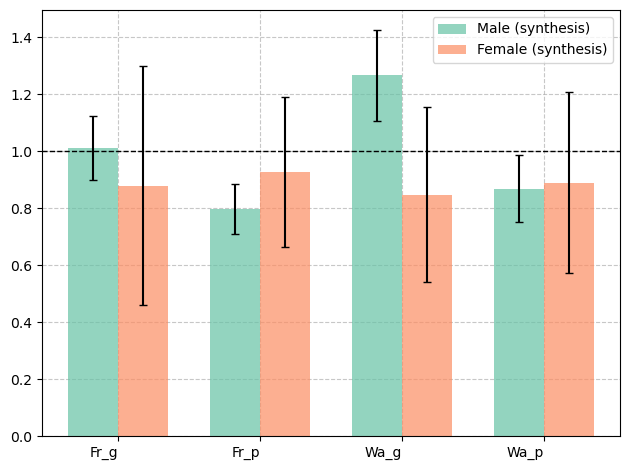

In [3]:
plot_gen_ratio("results_per_file_ratio.csv",
                metric="Silent Segment Count Norm",
                metric_err="Silent Segment Count Norm Err",
                plot_name="ratio_plot_with_bootstrap_pfr")
